# Data Preparation — BO : Prévenir le burn-out (Employee Attrition)
**Méthodologie CRISP-DM · Phase 3 : Data Preparation** (démarche du Chapitre 1)

- **BO** : Prévenir le burn-out
- **DSO** : Détecter les profils atypiques de surcharge (détection d'anomalies non supervisée)
- **Sortie attendue** : score d'anomalie + liste des employés atypiques
- **Jeu de données** : Employee Attrition (1 470 employés, 35 variables)

Plan : 0. Chargement · 1. Nettoyage · 2. Sélection de variables · 3. Transformation · 4. Feature engineering · 5. Réduction de dimension (PCA) · 6. Sauvegarde

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.decomposition import PCA
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

## 0. Chargement des données brutes (DataFrame) et audit qualité

In [2]:
# Jeu NON préparé : doublons, manquants, valeurs aberrantes et formats incohérents
df_raw = pd.read_csv('Employee_Attrition_non_prepare.csv')
df = df_raw.copy()
print(df.shape)
df.head()

(1490, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,34,No,Travel_Rarely,1303,Research & Development,2,4,Life Sciences,1,579,...,3,80,1,14,3,3,7,3,5.0,7
1,31,No,Travel_Rarely,655,Research & Development,7,4,Life Sciences,1,76,...,4,80,1,10,3,2,7,7,1.0,7
2,25,Yes,Travel_Rarely,383,Sales,9,2,Life Sciences,1,1439,...,1,80,0,6,2,3,3,2,2.0,2
3,35,No,Travel_Frequently,1182,Sales,11,2,Marketing,1,1137,...,4,80,1,5,3,3,5,2,0.0,2
4,38,No,Travel_Rarely,437,Sales,16,3,Life Sciences,1,1583,...,2,80,0,8,5,4,3,2,1.0,2


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1490 entries, 0 to 1489
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1490 non-null   int64  
 1   Attrition                 1490 non-null   str    
 2   BusinessTravel            1490 non-null   str    
 3   DailyRate                 1490 non-null   int64  
 4   Department                1461 non-null   str    
 5   DistanceFromHome          1490 non-null   int64  
 6   Education                 1490 non-null   int64  
 7   EducationField            1490 non-null   str    
 8   EmployeeCount             1490 non-null   int64  
 9   EmployeeNumber            1490 non-null   int64  
 10  EnvironmentSatisfaction   1490 non-null   int64  
 11  Gender                    1490 non-null   str    
 12  HourlyRate                1490 non-null   int64  
 13  JobInvolvement            1490 non-null   int64  
 14  JobLevel           

In [4]:
# Audit : valeurs manquantes
audit = pd.DataFrame({'manquants': df.isnull().sum(), '% manquants': (100*df.isnull().mean()).round(1)})
print('Lignes dupliquées (identiques) :', df.duplicated().sum())
print('EmployeeNumber uniques :', df['EmployeeNumber'].nunique(), 'sur', len(df), 'lignes')
audit[audit['manquants'] > 0]

Lignes dupliquées (identiques) : 20
EmployeeNumber uniques : 1470 sur 1490 lignes


,manquants,% manquants
Department,29,1.9
JobSatisfaction,45,3.0
MonthlyIncome,45,3.0
YearsSinceLastPromotion,29,1.9


In [5]:
# Audit : formats incohérents (catégories) et valeurs impossibles (numériques)
for c in ['BusinessTravel', 'OverTime']:
    print(c, df[c].value_counts(dropna=False).to_dict())
df[['Age', 'DistanceFromHome', 'MonthlyIncome']].describe().T[['min', 'max']]

BusinessTravel {'Travel_Rarely': 1032, 'Travel_Frequently': 272, 'Non-Travel': 145, ' TRAVEL_RARELY ': 26, ' TRAVEL_FREQUENTLY ': 9, ' NON-TRAVEL ': 6}
OverTime {'No': 1037, 'Yes': 412, 'no': 28, 'yes': 13}


,min,max
Age,-5.0,999.0
DistanceFromHome,1.0,9999.0
MonthlyIncome,-2500.0,19999.0


**Constats de l'audit :** (1) lignes dupliquées ; (2) `BusinessTravel` et `OverTime` écrits de plusieurs façons (espaces, majuscules/minuscules) ; (3) valeurs impossibles dans `Age`, `DistanceFromHome`, `MonthlyIncome` ; (4) valeurs manquantes dans `Department`, `JobSatisfaction`, `MonthlyIncome`, `YearsSinceLastPromotion`.

## 1. Data Cleaning
Au programme (Chap 1) : lignes dupliquées, colonnes redondantes/inutiles, valeurs aberrantes, valeurs manquantes.
**Règle suivie : on évite la suppression de lignes.** La seule suppression de lignes est celle des doublons exacts (justifiée plus bas).

### 1.1 Lignes dupliquées (redundant samples)

In [6]:
n_dup = df.duplicated().sum()
print('Doublons exacts :', n_dup)
print('EmployeeNumber uniques avant :', df['EmployeeNumber'].nunique(), 'sur', len(df))
df = df.drop_duplicates().reset_index(drop=True)
print('Après :', df.shape, '| EmployeeNumber uniques :', df['EmployeeNumber'].nunique())

Doublons exacts : 20
EmployeeNumber uniques avant : 1470 sur 1490
Après : (1470, 35) | EmployeeNumber uniques : 1470


**Justification de la suppression :** ces lignes sont des **copies exactes** (toutes les colonnes identiques, y compris `EmployeeNumber`) d'un employé déjà présent. Ce ne sont pas des observations différentes : les garder compterait deux fois la même personne et fausserait statistiques et modèle. Aucune information n'est perdue. Après suppression, chaque `EmployeeNumber` est unique.

### 1.2 Harmonisation des formats (catégories incohérentes)

In [7]:
df['BusinessTravel'] = df['BusinessTravel'].str.strip().str.title()
df['OverTime'] = df['OverTime'].str.strip().str.capitalize()
print(df['BusinessTravel'].value_counts().to_dict())
print(df['OverTime'].value_counts().to_dict())

{'Travel_Rarely': 1043, 'Travel_Frequently': 277, 'Non-Travel': 150}
{'No': 1054, 'Yes': 416}


Même modalité écrite différemment (`' TRAVEL_RARELY '`, `'no'`…) : on **corrige** sans supprimer ; sinon l'encodage créerait de fausses catégories.

### 1.3 Valeurs impossibles (hors domaine) → converties en valeurs manquantes

In [8]:
# Règles de validité métier
rules = {'Age': (18, 65), 'DistanceFromHome': (0, 100), 'MonthlyIncome': (1, np.inf)}
for c, (lo, hi) in rules.items():
    bad = (df[c] < lo) | (df[c] > hi)
    print(f'{c} : {bad.sum()} valeurs hors domaine ->', df.loc[bad, c].tolist())
    df.loc[bad, c] = np.nan   # on ne supprime pas la ligne : on traite la valeur comme manquante

Age : 4 valeurs hors domaine -> [-5, 150, 999, 0]
DistanceFromHome : 3 valeurs hors domaine -> [9999, 500, 300]
MonthlyIncome : 3 valeurs hors domaine -> [-1.0, -2500.0, 0.0]


Un âge de -5 ou 999, une distance de 9999 km ou un salaire négatif sont des **erreurs de saisie**. On ne supprime pas l'employé : on met seulement la valeur fautive à `NaN`, puis on l'impute avec les autres manquants.

### 1.4 Valeurs manquantes — imputation (pas de suppression)

In [9]:
miss = df.isnull().sum()
miss = miss[miss > 0]
pd.DataFrame({'manquants': miss, '% du jeu': (100*miss/len(df)).round(1)})

,manquants,% du jeu
Age,4,0.3
Department,29,2.0
DistanceFromHome,3,0.2
JobSatisfaction,44,3.0
MonthlyIncome,47,3.2
YearsSinceLastPromotion,29,2.0


In [10]:
# Department : déduit du JobRole (le poste détermine presque toujours le département)
role_to_dept = df.dropna(subset=['Department']).groupby('JobRole')['Department'].agg(lambda s: s.mode()[0])
df['Department'] = df['Department'].fillna(df['JobRole'].map(role_to_dept))

# JobSatisfaction : variable ordinale (1 à 4) -> valeur la plus fréquente
df[['JobSatisfaction']] = SimpleImputer(strategy='most_frequent').fit_transform(df[['JobSatisfaction']])

# MonthlyIncome : médiane du même niveau de poste (JobLevel, corrélation ~0.95 avec le salaire)
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df.groupby('JobLevel')['MonthlyIncome'].transform('median'))

# YearsSinceLastPromotion : médiane par YearsInCurrentRole (variables liées), plafonnée par YearsAtCompany
med = df['YearsSinceLastPromotion'].median()
by_role_years = df.groupby('YearsInCurrentRole')['YearsSinceLastPromotion'].transform('median').fillna(med)
df['YearsSinceLastPromotion'] = df['YearsSinceLastPromotion'].fillna(np.minimum(by_role_years, df['YearsAtCompany']))

# Age, DistanceFromHome : médiane (distributions asymétriques, quelques cas seulement)
for c in ['Age', 'DistanceFromHome']:
    df[c] = df[c].fillna(df[c].median())

# Types cohérents après imputation
for c in ['Age', 'DistanceFromHome', 'JobSatisfaction', 'YearsSinceLastPromotion', 'MonthlyIncome']:
    df[c] = df[c].round().astype(int)

assert df.isnull().sum().sum() == 0
print('Valeurs manquantes restantes :', df.isnull().sum().sum(), '| lignes conservées :', len(df))

Valeurs manquantes restantes : 0 | lignes conservées : 1470


**Justification (traitement des valeurs manquantes) :** aucune ligne n'est supprimée pour cause de manquant ou de valeur impossible. Supprimer des employés réduirait un échantillon déjà petit (1 470 lignes) et pourrait écarter justement les profils atypiques que l'on cherche (DSO : détection d'anomalies). Chaque variable reçoit une imputation adaptée à sa nature :

| Variable | Méthode | Pourquoi |
|---|---|---|
| `Department` | déduit du `JobRole` | le poste détermine le département (sauf `Manager`, où l'on prend le plus fréquent) |
| `JobSatisfaction` | valeur la plus fréquente | variable ordinale (1 à 4) : une moyenne n'aurait pas de sens |
| `MonthlyIncome` | médiane par `JobLevel` | le salaire dépend fortement du niveau de poste (r ≈ 0.95) ; la médiane résiste aux valeurs extrêmes |
| `YearsSinceLastPromotion` | médiane par `YearsInCurrentRole`, plafonnée par `YearsAtCompany` | distribution asymétrique ; le délai depuis la promotion suit le temps passé dans le poste et ne peut pas dépasser l'ancienneté |
| `Age`, `DistanceFromHome` | médiane | peu de cas, distributions asymétriques |

### 1.5 Colonnes redondantes / inutiles (redundant features)

In [11]:
# Colonnes dupliquées (même contenu)
dup_cols = df.columns[df.T.duplicated()]
print('Colonnes dupliquées :', list(dup_cols))

# Colonnes constantes
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print('Colonnes constantes :', const_cols)

# Identifiant : aucune valeur prédictive
id_cols = ['EmployeeNumber']
df = df.drop(columns=const_cols + id_cols + list(dup_cols))
df.shape

Colonnes dupliquées : []


Colonnes constantes : ['EmployeeCount', 'Over18', 'StandardHours']


(1470, 31)

### 1.6 Valeurs aberrantes (outliers) — méthode IQR + boxplots

In [12]:
num_cols = df.select_dtypes(include='number').columns
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    if n: rows.append((c, n, round(100*n/len(df), 1)))
pd.DataFrame(rows, columns=['variable', 'nb_outliers', '%']).sort_values('nb_outliers', ascending=False)

,variable,nb_outliers,%
5,TrainingTimesLastYear,238,16.2
2,PerformanceRating,226,15.4
0,MonthlyIncome,110,7.5
8,YearsSinceLastPromotion,105,7.1
6,YearsAtCompany,104,7.1
3,StockOptionLevel,85,5.8
4,TotalWorkingYears,63,4.3
1,NumCompaniesWorked,52,3.5
7,YearsInCurrentRole,21,1.4
9,YearsWithCurrManager,14,1.0


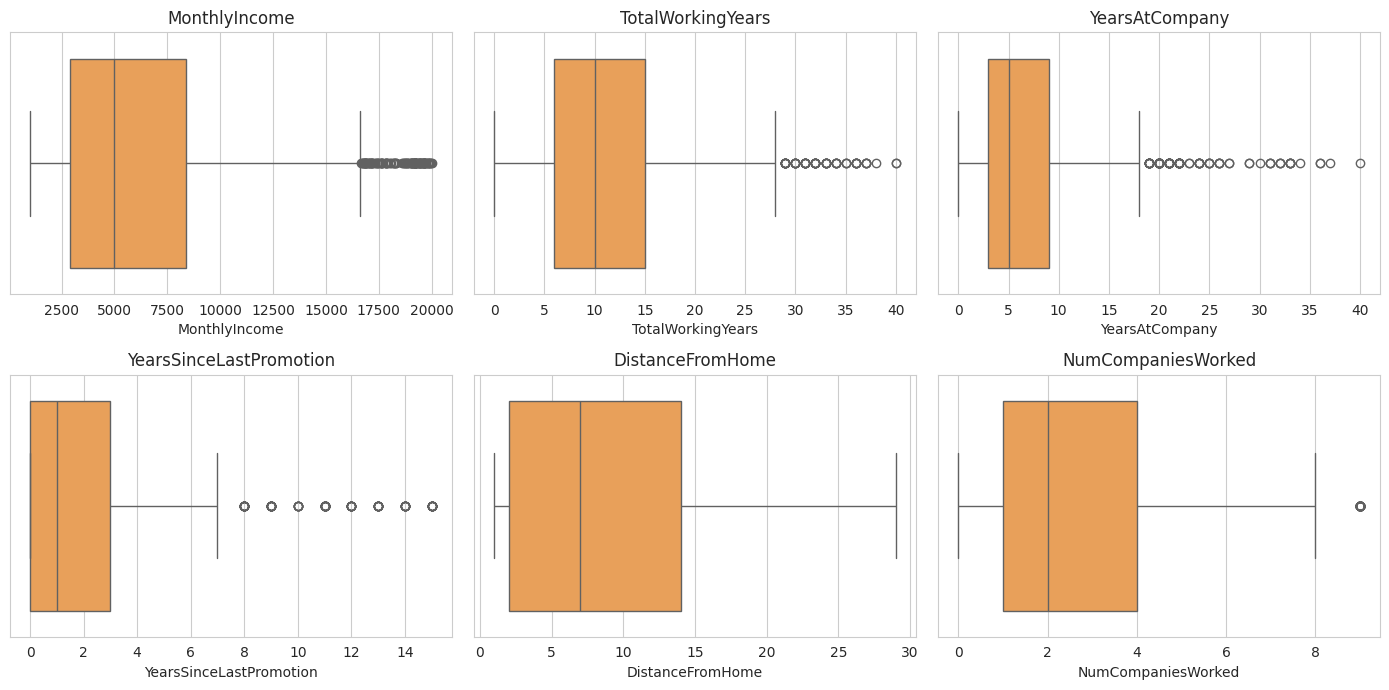

In [13]:
cols = ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion', 'DistanceFromHome', 'NumCompaniesWorked']
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax.ravel(), cols):
    sns.boxplot(x=df[c], ax=a, color='#ff9f43'); a.set_title(c)
plt.tight_layout(); plt.show()

*Remarque :* `PerformanceRating` (valeurs 3 ou 4), `StockOptionLevel` et `TrainingTimesLastYear` sont des variables discrètes à très peu de valeurs : l'IQR les signale à tort comme « outliers ». (`YearsSinceLastPromotion` est aussi discrète et très asymétrique : son troisième quartile est à la frontière entre 2 et 3, donc le nombre d'outliers IQR est sensible et reste indicatif.) Les vrais cas continus sont surtout `MonthlyIncome`, `YearsAtCompany`, `YearsSinceLastPromotion`, `TotalWorkingYears`.

**Décision :** on **conserve** les outliers. Pour la détection d'anomalies (notre DSO), les profils extrêmes sont justement ce que l'on cherche : les supprimer ou les plafonner détruirait le signal. Ce sont de vraies observations (salaires élevés, longue ancienneté). Les valeurs **impossibles** (âge 999, salaire négatif…) ont déjà été corrigées en 1.3 : ce sont des erreurs, pas des outliers.

In [14]:
df.to_csv('Employee_Attrition_clean.csv', index=False)   # jeu nettoyé (checkpoint)
print(df.shape)

(1470, 31)


## 2. Feature Selection
Filtre statistique (corrélation) pour repérer les variables redondantes, puis sélection métier pour le burn-out.

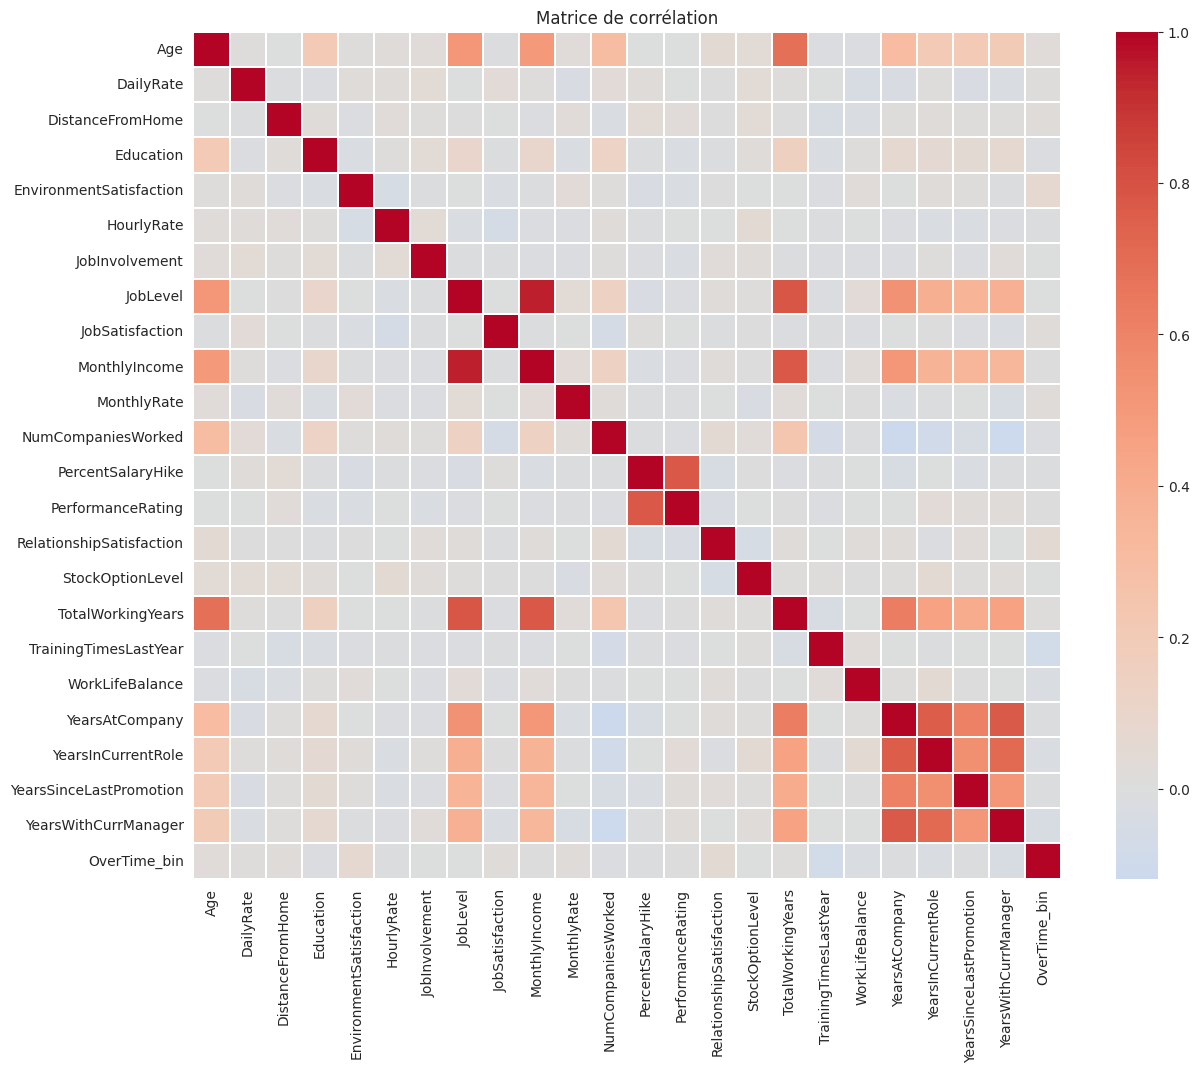

In [15]:
df['OverTime_bin'] = (df['OverTime'] == 'Yes').astype(int)  # temporaire pour la corrélation
corr = df.select_dtypes(include='number').corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=.2)
plt.title('Matrice de corrélation'); plt.show()

In [16]:
# Paires fortement corrélées (|r| > 0.7)
c = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = c.stack().reset_index(); pairs.columns = ['var1', 'var2', 'r']
pairs[pairs['r'] > 0.7].sort_values('r', ascending=False)

,var1,var2,r
177,JobLevel,MonthlyIncome,0.951707
184,JobLevel,TotalWorkingYears,0.782208
232,MonthlyIncome,TotalWorkingYears,0.773701
301,PercentSalaryHike,PerformanceRating,0.773550
478,YearsAtCompany,YearsWithCurrManager,0.769212
476,YearsAtCompany,YearsInCurrentRole,0.758754
502,YearsInCurrentRole,YearsWithCurrManager,0.714365


Paires fortement corrélées trouvées : `JobLevel` ↔ `MonthlyIncome` (0.95), `JobLevel` ↔ `TotalWorkingYears` (0.78), `PercentSalaryHike` ↔ `PerformanceRating` (0.77), `YearsAtCompany` ↔ `YearsWithCurrManager` / `YearsInCurrentRole` (≈ 0.76-0.77).

**Décision :** on retire `JobLevel` (redondant avec `MonthlyIncome`), `PerformanceRating` (redondant avec `PercentSalaryHike`, et seulement 2 valeurs), `YearsWithCurrManager` et `YearsInCurrentRole` (redondants avec `YearsAtCompany`).

In [17]:
# Variables liées à la charge de travail / bien-être (burn-out), validées avec le BO
burnout_features = [
    # Cœur du BO
    'OverTime', 'BusinessTravel', 'WorkLifeBalance', 'EnvironmentSatisfaction',
    # Compléments pertinents pour la surcharge
    'JobSatisfaction', 'JobInvolvement', 'DistanceFromHome', 'YearsSinceLastPromotion',
    'YearsAtCompany', 'TotalWorkingYears', 'NumCompaniesWorked', 'MonthlyIncome',
    'Age', 'PercentSalaryHike', 'TrainingTimesLastYear', 'StockOptionLevel',
    'RelationshipSatisfaction', 'JobRole', 'Department', 'MaritalStatus', 'Gender']
df_bo = df[burnout_features + ['Attrition']].copy()   # Attrition gardée SEULEMENT pour la validation a posteriori
df_bo.shape

(1470, 22)

## 3. Data Transformation
Encodage des variables catégorielles (ordinal vs nominal) puis mise à l'échelle.

### 3.1 Encodage des variables catégorielles

In [18]:
# Cible de validation + binaires
df_bo['Attrition'] = df_bo['Attrition'].map({'No': 0, 'Yes': 1})
df_bo['OverTime'] = df_bo['OverTime'].map({'No': 0, 'Yes': 1})
df_bo['Gender'] = df_bo['Gender'].map({'Female': 0, 'Male': 1})

# ORDINAL -> OrdinalEncoder (ordre explicite)
enc_ord = OrdinalEncoder(categories=[['Non-Travel', 'Travel_Rarely', 'Travel_Frequently']])
df_bo['BusinessTravel'] = enc_ord.fit_transform(df_bo[['BusinessTravel']]).ravel()

# NOMINAL -> One-Hot
nominal = ['JobRole', 'Department', 'MaritalStatus']
df_enc = pd.get_dummies(df_bo, columns=nominal, drop_first=True, dtype=int)
print(df_enc.shape)
df_enc.head()

(1470, 31)


,OverTime,BusinessTravel,WorkLifeBalance,EnvironmentSatisfaction,JobSatisfaction,JobInvolvement,DistanceFromHome,YearsSinceLastPromotion,YearsAtCompany,TotalWorkingYears,...,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,Department_Research & Development,Department_Sales,MaritalStatus_Married,MaritalStatus_Single
0,0,1.0,3,4,3,2,2,5,7,14,...,0,0,0,1,0,0,1,0,0,0
1,0,1.0,2,4,4,3,7,1,7,10,...,0,0,0,0,0,0,1,0,0,0
2,0,1.0,3,1,4,2,9,2,3,6,...,0,0,0,0,0,1,0,1,1,0
3,0,2.0,3,4,4,3,11,0,5,5,...,0,0,0,0,1,0,0,1,0,0
4,0,1.0,4,2,2,3,16,1,3,8,...,0,0,0,0,1,0,0,1,0,1


### 3.2 Mise à l'échelle (Standardisation : z = (x − μ) / σ)

In [19]:
y_attr = df_enc['Attrition']              # gardée à part (validation)
X = df_enc.drop(columns=['Attrition'])

to_scale = ['DistanceFromHome', 'YearsSinceLastPromotion', 'YearsAtCompany', 'TotalWorkingYears',
            'NumCompaniesWorked', 'MonthlyIncome', 'Age', 'PercentSalaryHike', 'TrainingTimesLastYear']
X_scaled = X.copy()
X_scaled[to_scale] = StandardScaler().fit_transform(X[to_scale])
X_scaled[to_scale].describe().loc[['mean', 'std']].round(2)

,DistanceFromHome,YearsSinceLastPromotion,YearsAtCompany,TotalWorkingYears,NumCompaniesWorked,MonthlyIncome,Age,PercentSalaryHike,TrainingTimesLastYear
mean,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


*Remarque :* Isolation Forest (arbres) n'exige pas de mise à l'échelle, mais la standardisation est **obligatoire pour la PCA** (étape 5) et utile pour comparer d'autres méthodes (LOF, One-Class SVM).

## 4. Feature Engineering
Création de variables qui représentent mieux la **surcharge** (somme, quotient, indicateurs).

In [20]:
fe = X_scaled.copy()
raw = X   # valeurs non standardisées pour construire des ratios lisibles

# Score de bien-être : moyenne des satisfactions (1 à 4)
fe['WellBeingScore'] = raw[['WorkLifeBalance', 'EnvironmentSatisfaction', 'JobSatisfaction', 'RelationshipSatisfaction']].mean(axis=1)

# Indice de surcharge : heures sup. + déplacements + faible équilibre vie pro/perso
fe['OverloadIndex'] = raw['OverTime']*2 + raw['BusinessTravel'] + (5 - raw['WorkLifeBalance'])

# Stagnation : années depuis la dernière promotion rapportées à l'ancienneté
fe['PromotionStagnation'] = raw['YearsSinceLastPromotion'] / (raw['YearsAtCompany'] + 1)

# Fréquence de changement d'employeur
fe['JobHoppingRate'] = raw['NumCompaniesWorked'] / (raw['TotalWorkingYears'] + 1)

# Trajet pénible : distance élevée (> 20 km)
fe['LongCommute'] = (raw['DistanceFromHome'] > 20).astype(int)

new_feats = ['WellBeingScore', 'OverloadIndex', 'PromotionStagnation', 'JobHoppingRate', 'LongCommute']
fe[new_feats].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
WellBeingScore,1470.0,2.74,0.51,1.0,2.50,2.75,3.00,4.00
OverloadIndex,1470.0,3.89,1.29,1.0,3.00,4.00,5.00,8.00
PromotionStagnation,1470.0,0.23,0.27,0.0,0.00,0.14,0.42,0.92
JobHoppingRate,1470.0,0.28,0.29,0.0,0.09,0.18,0.39,2.25
LongCommute,1470.0,0.14,0.35,0.0,0.00,0.00,0.00,1.00


In [21]:
# Nouvelles variables : standardiser celles qui sont continues
fe[['WellBeingScore', 'OverloadIndex', 'PromotionStagnation', 'JobHoppingRate']] = StandardScaler().fit_transform(
    fe[['WellBeingScore', 'OverloadIndex', 'PromotionStagnation', 'JobHoppingRate']])
print(fe.shape)

(1470, 35)


## 5. Dimensionality Reduction : PCA
Étapes du cours : standardisation → valeurs/vecteurs propres → tri → projection. On choisit le nombre de composantes avec **la variance expliquée cumulée**, le **scree plot** et la **règle de Kaiser**.

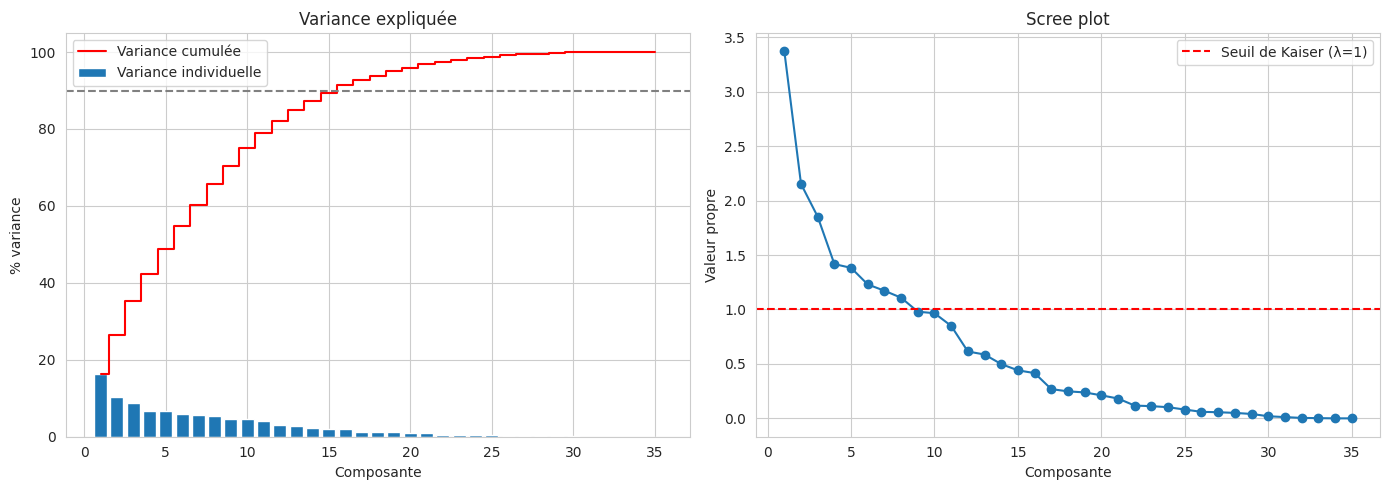

Composantes pour 90 % de variance : 16
Composantes selon Kaiser (λ>1)   : 8


In [22]:
pca_full = PCA().fit(fe)
var = pca_full.explained_variance_ratio_
cum = np.cumsum(var)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(range(1, len(var)+1), var*100, label='Variance individuelle')
ax[0].step(range(1, len(var)+1), cum*100, where='mid', color='red', label='Variance cumulée')
ax[0].axhline(90, ls='--', color='gray'); ax[0].set_xlabel('Composante'); ax[0].set_ylabel('% variance'); ax[0].legend()
ax[0].set_title('Variance expliquée')

ax[1].plot(range(1, len(var)+1), pca_full.explained_variance_, 'o-')
ax[1].axhline(1, ls='--', color='red', label='Seuil de Kaiser (λ=1)'); ax[1].legend()
ax[1].set_xlabel('Composante'); ax[1].set_ylabel('Valeur propre'); ax[1].set_title('Scree plot')
plt.tight_layout(); plt.show()

k90 = int(np.argmax(cum >= 0.90) + 1)
kaiser = int((pca_full.explained_variance_ > 1).sum())
print(f'Composantes pour 90 % de variance : {k90}')
print(f'Composantes selon Kaiser (λ>1)   : {kaiser}')

In [23]:
# On retient le nombre de composantes pour 90 % de variance
pca = PCA(n_components=0.90)
X_pca = pd.DataFrame(pca.fit_transform(fe), columns=[f'PC{i+1}' for i in range(pca.n_components_)])
print('Dimensions :', fe.shape[1], '->', X_pca.shape[1])
print('Variance conservée :', round(pca.explained_variance_ratio_.sum()*100, 1), '%')

Dimensions : 35 -> 16
Variance conservée : 91.3 %


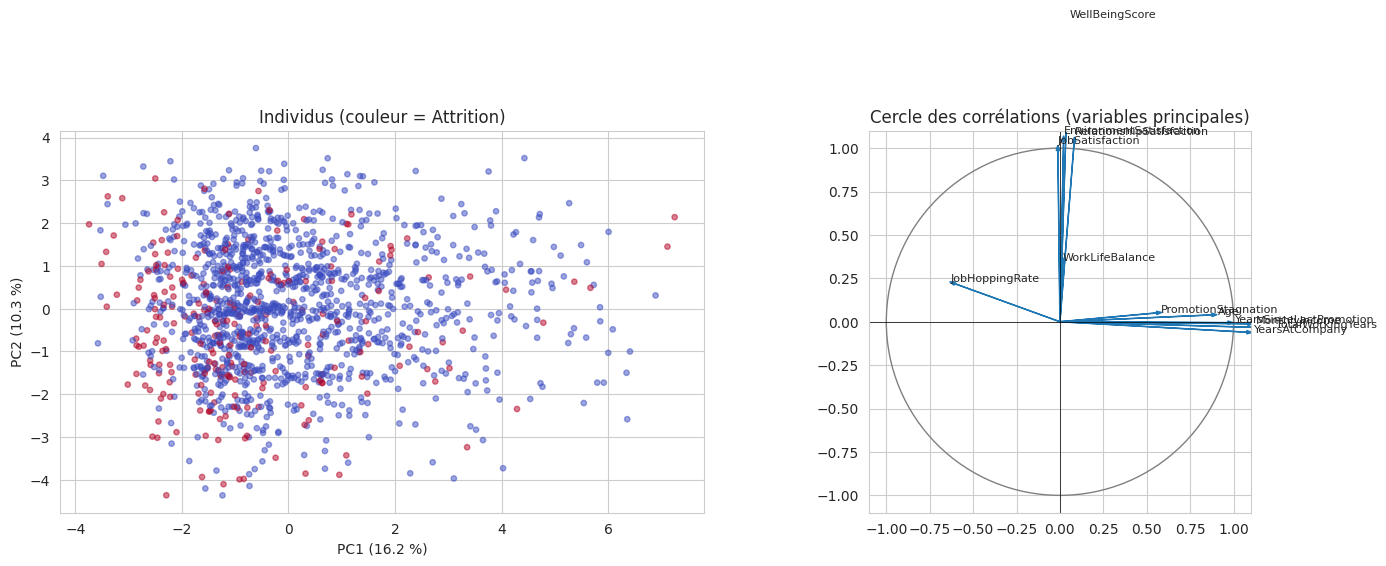

In [24]:
# Cercle des corrélations (PC1, PC2) + projection des individus
loadings = pd.DataFrame(pca.components_[:2].T, index=fe.columns, columns=['PC1', 'PC2'])
sc = pca.transform(fe)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].scatter(sc[:, 0], sc[:, 1], c=y_attr, cmap='coolwarm', alpha=.5, s=15)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)'); ax[0].set_title('Individus (couleur = Attrition)')

top = (loadings**2).sum(axis=1).sort_values(ascending=False).head(12).index
ax[1].add_patch(plt.Circle((0, 0), 1, fill=False, color='gray'))
for v in top:
    ax[1].arrow(0, 0, loadings.loc[v, 'PC1']*2.5, loadings.loc[v, 'PC2']*2.5, head_width=.02, color='tab:blue')
    ax[1].text(loadings.loc[v, 'PC1']*2.6, loadings.loc[v, 'PC2']*2.6, v, fontsize=8)
ax[1].set_xlim(-1.1, 1.1); ax[1].set_ylim(-1.1, 1.1); ax[1].set_aspect('equal')
ax[1].axhline(0, color='k', lw=.5); ax[1].axvline(0, color='k', lw=.5); ax[1].set_title('Cercle des corrélations (variables principales)')
plt.tight_layout(); plt.show()

**Lecture :** plus une variable est proche du bord du cercle, mieux elle est représentée par le plan factoriel ; l'angle entre deux flèches traduit leur corrélation. Les variables de surcharge (`OverTime`, `OverloadIndex`, `WellBeingScore`) devraient se démarquer sur les premiers axes.

## 6. Sauvegarde des données préparées (Data storage)

In [25]:
fe.to_csv('employee_prepared_burnout.csv', index=False)          # jeu complet préparé (pour Isolation Forest)
X_pca.to_csv('employee_prepared_burnout_pca.csv', index=False)   # version réduite par PCA
y_attr.to_csv('employee_attrition_label.csv', index=False)       # label gardé pour validation a posteriori
print('Fichiers sauvegardés.', fe.shape, X_pca.shape)

Fichiers sauvegardés. (1470, 35) (1470, 16)


## Conclusion de la préparation
| Étape | Action réalisée |
|---|---|
| Nettoyage | 0 valeur manquante, 0 doublon ; retrait de `EmployeeCount`, `StandardHours`, `Over18`, `EmployeeNumber` ; outliers conservés (utiles à la détection d'anomalies) |
| Sélection | Variables liées à la charge et au bien-être ; corrélations fortes repérées |
| Transformation | Binaire (OverTime, Gender), ordinal (BusinessTravel), one-hot (JobRole, Department, MaritalStatus), standardisation |
| Feature engineering | `WellBeingScore`, `OverloadIndex`, `PromotionStagnation`, `JobHoppingRate`, `LongCommute` |
| Réduction | PCA conservant 90 % de la variance |

**Prochaine étape (Modeling)** : Isolation Forest (`contamination`, `n_estimators`, `max_samples`) → score d'anomalie et liste des employés atypiques de surcharge.

---
# Phase 4 : Modeling — BO : Prévenir le burn-out

- **BO** : Prévenir le burn-out
- **DSO** : Détecter les employés au profil atypique de surcharge (détection d'anomalies **non supervisée**)
- **Pourquoi non supervisé ?** Le jeu ne contient aucune colonne « burn-out » : une classification est impossible.

**Deux modèles comparés :**

| | Modèle 1 | Modèle 2 |
|---|---|---|
| Algorithme | **Isolation Forest** | **LOF** (Local Outlier Factor) |
| Principe | isolement par coupures aléatoires | densité locale par rapport aux voisins |
| Données d'entrée | `fe` sans variables nominales ni `Gender` | `X_pca` (90 % de variance) |

In [ ]:
import time
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score

CONTAMINATION = 0.05   # ~5 % d'employés signalés (≈ 70 personnes : une liste que les RH peuvent traiter)
SEED = 42

# Entrée du modèle 1 : on retire les variables nominales (one-hot) et Gender
# -> un poste rare serait isolé parce qu'il est rare, pas parce qu'il y a surcharge ; Gender est un attribut sensible
cols_B = [c for c in fe.columns if not c.startswith(('JobRole_', 'Department_', 'MaritalStatus_', 'Gender'))]
XB = fe[cols_B]
print('Isolation Forest :', XB.shape[1], 'variables | LOF :', X_pca.shape[1], 'composantes PCA')

## 4.1 Modèle 1 — Isolation Forest

**Principe.** On construit de nombreux arbres ; à chaque nœud, une variable et un seuil sont choisis au hasard. Un employé atypique est isolé en peu de coupures (chemin court), un employé normal en beaucoup. Le score d'anomalie vient de la longueur moyenne du chemin.

**Pourquoi ce choix.**
- Non supervisé : il n'a pas besoin de colonne « burn-out ».
- Il exploite les outliers conservés au nettoyage : ce sont les profils recherchés.
- Il utilise les variables de surcharge créées au Feature Engineering (`OverloadIndex`, `WellBeingScore`).
- Rapide, explicable par variable, et il donne un score pour classer les employés.

**Paramètres.** `n_estimators=300` (score plus stable), `max_samples=256`, `contamination=0.05`, `random_state=42`.

In [ ]:
t0 = time.perf_counter()
iso = IsolationForest(n_estimators=300, max_samples=256, contamination=CONTAMINATION, random_state=SEED).fit(XB)
t_if = time.perf_counter() - t0

res = fe.copy()
res['if_score']   = -iso.score_samples(XB)               # plus haut = plus atypique
res['if_anomaly'] = (iso.predict(XB) == -1).astype(int)  # 1 = atypique
print('Isolation Forest : employés signalés =', res['if_anomaly'].sum(), 'sur', len(res))

## 4.2 Modèle 2 — LOF (Local Outlier Factor)

**Principe.** Pour chaque employé, LOF compare la densité autour de lui à celle de ses `k` plus proches voisins. S'il est dans une zone bien plus vide que ses voisins, il est atypique.

**Pourquoi ce choix.**
- Approche différente d'Isolation Forest (distances et densité) : si les deux modèles s'accordent, le résultat est plus solide.
- Détecte les anomalies **locales** (atypique par rapport à son groupe proche).
- Il s'appuie sur la standardisation et la PCA faites en Data Preparation (les distances sont plus fiables en dimension réduite).

**Paramètres.** `n_neighbors=20`, `contamination=0.05` (même seuil pour comparer).

In [ ]:
t0 = time.perf_counter()
lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINATION)
res['lof_anomaly'] = (lof.fit_predict(X_pca) == -1).astype(int)
t_lof = time.perf_counter() - t0
res['lof_score'] = -lof.negative_outlier_factor_           # plus haut = plus atypique
print('LOF : employés signalés =', res['lof_anomaly'].sum(), 'sur', len(res))

## 4.3 Grille d'évaluation

**Pourquoi pas précision / recall / F1 ?** Ces métriques demandent une colonne qui dit « cet employé est en burn-out ». Elle n'existe pas dans les données (`Attrition` = départ, pas burn-out). On évalue donc avec des métriques adaptées, sur **trois niveaux** :

1. **Validité métier** : les employés signalés sont-ils vraiment en surcharge ?
2. **Fiabilité** : le modèle est-il stable (mêmes employés si on change de graine ou de `k`) et rapide ?
3. **Proxy `Attrition`** : les signalés quittent-ils plus souvent l'entreprise ? C'est un **indice**, pas une preuve, donc une valeur modeste est normale.

In [ ]:
def jaccard(a, b):
    return len(a & b) / len(a | b)

taux_global = y_attr.mean()
grille = {}
for nom, score, flag in [('Isolation Forest', 'if_score', 'if_anomaly'), ('LOF', 'lof_score', 'lof_anomaly')]:
    s = res[flag] == 1
    grille[nom] = {
        '1. % signalés en heures sup.':           round(res.loc[s, 'OverTime'].mean() * 100, 1),
        '1. OverloadIndex moyen (signalés)':      round(res.loc[s, 'OverloadIndex'].mean(), 2),
        '1. WellBeingScore moyen (signalés)':     round(res.loc[s, 'WellBeingScore'].mean(), 2),
        "3. Taux d'attrition des signalés":        round(y_attr[s].mean(), 3),
        '3. Lift (taux signalés / taux global)':  round(y_attr[s].mean() / taux_global, 2),
        '3. ROC-AUC (score vs Attrition)':        round(roc_auc_score(y_attr, res[score]), 3),
    }

# 2. Stabilité : IF avec 5 graines différentes, LOF avec 2 autres valeurs de k
ref_if  = set(res.index[res['if_anomaly'] == 1])
ref_lof = set(res.index[res['lof_anomaly'] == 1])
j_if  = [jaccard(ref_if, set(res.index[IsolationForest(n_estimators=300, contamination=CONTAMINATION, random_state=s).fit(XB).predict(XB) == -1]))
         for s in range(5)]
j_lof = [jaccard(ref_lof, set(res.index[LocalOutlierFactor(n_neighbors=k, contamination=CONTAMINATION).fit_predict(X_pca) == -1]))
         for k in (10, 30)]
grille['Isolation Forest']['2. Stabilité (Jaccard, 0 à 1)'] = round(sum(j_if) / len(j_if), 3)
grille['LOF']['2. Stabilité (Jaccard, 0 à 1)']              = round(sum(j_lof) / len(j_lof), 3)
grille['Isolation Forest']['2. Temps d\'exécution (s)'] = round(t_if, 3)
grille['LOF']['2. Temps d\'exécution (s)']              = round(t_lof, 3)
grille['Isolation Forest']['2. Interprétabilité'] = 'Bonne (par variable)'
grille['LOF']['2. Interprétabilité']              = 'Moyenne (distances)'

grille = pd.DataFrame(grille).sort_index()
display(grille)

print('Référence (tous les employés) : % heures sup. =', round(res['OverTime'].mean() * 100, 1),
      '| OverloadIndex moyen =', round(res['OverloadIndex'].mean(), 2),
      '| taux d\'attrition global =', round(taux_global, 3))

## 4.4 Comparaison des deux modèles et liste prioritaire

Les employés signalés par **les deux modèles** forment la liste prioritaire de profils à risque de burn-out.

In [ ]:
les_deux = ((res.if_anomaly == 1) & (res.lof_anomaly == 1)).sum()
print('Signalés par les deux modèles :', les_deux)
print('Isolation Forest seul         :', ((res.if_anomaly == 1) & (res.lof_anomaly == 0)).sum())
print('LOF seul                      :', ((res.if_anomaly == 0) & (res.lof_anomaly == 1)).sum())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, col, titre in zip(ax, ['if_anomaly', 'lof_anomaly'], ['Isolation Forest', 'LOF']):
    a.scatter(X_pca['PC1'], X_pca['PC2'], c=res[col], cmap='coolwarm', s=15, alpha=.6)
    a.set_title(titre + ' (rouge = atypique)'); a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.tight_layout(); plt.show()

s = (res.if_anomaly == 1) & (res.lof_anomaly == 1)
print('Liste prioritaire (les deux modèles) :', s.sum(), 'employés | heures sup. =', round(res.loc[s, 'OverTime'].mean() * 100, 1),
      '% | OverloadIndex moyen =', round(res.loc[s, 'OverloadIndex'].mean(), 2), '| attrition =', round(y_attr[s].mean(), 3))

liste_prioritaire = res[(res.if_anomaly == 1) & (res.lof_anomaly == 1)].sort_values('if_score', ascending=False)
liste_prioritaire[['if_score', 'lof_score', 'OverTime', 'OverloadIndex', 'WellBeingScore']].head(10).round(2)

---
# Phase 6 : Deployment — export des deux modèles pour l'application Streamlit

L'enseignante demande les **deux modèles** dans l'application. Ce qui est fait ici :
- **Isolation Forest** est exporté tel quel (il sait évaluer de nouveaux employés).
- **LOF** est refait en mode `novelty=True` : le `fit_predict` utilisé pour la comparaison ne permet pas de scorer de nouvelles données. Comme LOF travaille sur la PCA, la **PCA** est exportée aussi.
- La préparation (standardisation, Feature Engineering) est refaite à l'identique dans `burnout_utils.py`, et **vérifiée** contre les résultats du notebook avant toute sauvegarde.

**Fichiers produits** (dans le dossier du notebook) : `burnout_utils.py`, `burnout_model.joblib`, `requirements.txt`, `app.py`.

In [ ]:
%%writefile burnout_utils.py
"""Fonctions partagées entre le notebook (export) et l'application Streamlit.
Elles reproduisent EXACTEMENT la Data Preparation du notebook : standardisation, Feature Engineering, PCA."""
import pandas as pd

NEW_SCALED = ['WellBeingScore', 'OverloadIndex', 'PromotionStagnation', 'JobHoppingRate']


def creer_features_brutes(raw):
    """Les 5 variables du Feature Engineering, calculées sur les valeurs brutes (non standardisées)."""
    out = pd.DataFrame(index=raw.index)
    out['WellBeingScore'] = raw[['WorkLifeBalance', 'EnvironmentSatisfaction',
                                 'JobSatisfaction', 'RelationshipSatisfaction']].mean(axis=1)
    out['OverloadIndex'] = raw['OverTime'] * 2 + raw['BusinessTravel'] + (5 - raw['WorkLifeBalance'])
    out['PromotionStagnation'] = raw['YearsSinceLastPromotion'] / (raw['YearsAtCompany'] + 1)
    out['JobHoppingRate'] = raw['NumCompaniesWorked'] / (raw['TotalWorkingYears'] + 1)
    out['LongCommute'] = (raw['DistanceFromHome'] > 20).astype(int)
    return out


def preparer_fe(raw, bundle):
    """raw : DataFrame de valeurs brutes (mêmes colonnes que X dans le notebook).
    Retourne le jeu préparé `fe` (mêmes colonnes et même ordre qu'au notebook)."""
    fe_new = raw.copy().astype(float)
    fe_new[bundle['to_scale']] = bundle['scaler_base'].transform(raw[bundle['to_scale']])
    nouvelles = creer_features_brutes(raw).astype(float)
    nouvelles[NEW_SCALED] = bundle['scaler_new'].transform(nouvelles[NEW_SCALED])
    for c in nouvelles.columns:
        fe_new[c] = nouvelles[c]
    return fe_new[bundle['cols_fe']]


def entree_if(fe_new, bundle):
    """Entrée du Modèle 1 (Isolation Forest) = config B."""
    return fe_new[bundle['cols_B']]


def entree_lof(fe_new, bundle):
    """Entrée du Modèle 2 (LOF) = projection PCA (90 % de variance)."""
    return pd.DataFrame(bundle['pca'].transform(fe_new), columns=bundle['cols_pca'], index=fe_new.index)


def scorer(raw, bundle):
    """Retourne (score Isolation Forest, score LOF) : plus haut = plus atypique."""
    fe_new = preparer_fe(raw, bundle)
    s_if = -bundle['model_if'].score_samples(entree_if(fe_new, bundle))
    s_lof = -bundle['model_lof'].score_samples(entree_lof(fe_new, bundle))
    return s_if, s_lof

In [ ]:
import importlib, joblib, sklearn
importlib.invalidate_caches()
from sklearn.preprocessing import StandardScaler
from burnout_utils import creer_features_brutes, preparer_fe, entree_if, entree_lof, NEW_SCALED

# Modèle 2 : LOF refait en mode "novelty" pour pouvoir évaluer de NOUVEAUX employés
# (fit_predict, utilisé plus haut pour comparer les modèles, ne permet pas de scorer de nouvelles données)
lof_deploy = LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINATION, novelty=True).fit(X_pca.values)

# Les 2 StandardScaler de la Data Preparation, refaits à l'identique (mêmes données, même calcul)
scaler_base = StandardScaler().fit(X[to_scale])
scaler_new  = StandardScaler().fit(creer_features_brutes(X)[NEW_SCALED])

bundle = {
    'model_if': iso,                                   # Modèle 1 : Isolation Forest
    'model_lof': lof_deploy,                           # Modèle 2 : LOF (novelty=True)
    'pca': pca,                                        # PCA 90 % de variance (entrée du LOF)
    'cols_B': cols_B,                                  # variables de l'Isolation Forest
    'cols_fe': list(fe.columns),                       # colonnes du jeu préparé (entrée de la PCA)
    'cols_pca': list(X_pca.columns),
    'to_scale': to_scale,
    'scaler_base': scaler_base,
    'scaler_new': scaler_new,
    'defaults': X.median(),                            # valeurs par défaut des variables non saisies dans l'application
    'categories': {c: sorted(df_bo[c].unique()) for c in ['JobRole', 'Department', 'MaritalStatus']},
    'role_to_dept': df_bo.groupby('JobRole')['Department'].agg(lambda s: s.mode()[0]).to_dict(),
    'seuil_if': -iso.offset_,                          # score au-dessus duquel un employé est signalé
    'seuil_lof': -lof_deploy.offset_,
    'scores_ref_if': res['if_score'].values,           # scores du jeu d'entraînement (pour calculer le percentile)
    'scores_ref_lof': res['lof_score'].values,
    'sklearn_version': sklearn.__version__,
}

# Vérifications : le pipeline de l'application doit reproduire EXACTEMENT les résultats du notebook
fe_chk = preparer_fe(X, bundle)
checks = {
    'Préparation des données (fe)': np.allclose(fe_chk.values, fe.astype(float).values),
    'Scores Isolation Forest':      np.allclose(-iso.score_samples(entree_if(fe_chk, bundle)), res['if_score']),
    'Projection PCA (entrée LOF)':  np.allclose(entree_lof(fe_chk, bundle).values, X_pca.values),
    'Scores LOF':                   np.allclose(-lof_deploy.negative_outlier_factor_, res['lof_score']),
}
for nom, ok in checks.items():
    print(('OK      ' if ok else 'ERREUR  ') + nom)

if all(checks.values()):
    joblib.dump(bundle, 'burnout_model.joblib')
    with open('requirements.txt', 'w') as f:
        f.write(f"streamlit\npandas\nnumpy\nscikit-learn=={sklearn.__version__}\njoblib\n")
    print('\nFichiers créés : burnout_model.joblib et requirements.txt (scikit-learn', sklearn.__version__ + ')')
else:
    print('\nAucun fichier créé : copie-moi ce résultat pour que je corrige.')

In [ ]:
%%writefile app.py
import sys
from pathlib import Path

# Le dossier de ce fichier (permet de lancer l'application depuis n'importe où, ex. depuis un sous-dossier BO2/)
DOSSIER = Path(__file__).resolve().parent
sys.path.insert(0, str(DOSSIER))

import joblib
import pandas as pd
import streamlit as st
from burnout_utils import scorer, creer_features_brutes

st.set_page_config(page_title="Prévention du burn-out", page_icon="🧠", layout="centered")


@st.cache_resource
def charger():
    return joblib.load(DOSSIER / 'burnout_model.joblib')


bundle = charger()
d = bundle['defaults']
cat = bundle['categories']
TRAVEL = ["Non-Travel", "Travel_Rarely", "Travel_Frequently"]

st.title("🧠 Prévention du burn-out")
st.write("Outil d'aide à la décision pour les RH : deux modèles de détection d'anomalies "
         "(**Isolation Forest** et **LOF**) repèrent les profils de travail atypiques "
         "à partir du jeu Employee Attrition.")

with st.form("formulaire"):
    st.subheader("Profil de l'employé")
    c1, c2 = st.columns(2)
    with c1:
        overtime = st.radio("Heures supplémentaires", ["Non", "Oui"], horizontal=True)
        travel = st.selectbox("Déplacements professionnels", TRAVEL, index=1)
        wlb = st.slider("Équilibre vie pro / perso (1 = mauvais, 4 = excellent)", 1, 4, int(round(d['WorkLifeBalance'])))
        env = st.slider("Satisfaction de l'environnement (1 à 4)", 1, 4, int(round(d['EnvironmentSatisfaction'])))
        job = st.slider("Satisfaction au travail (1 à 4)", 1, 4, int(round(d['JobSatisfaction'])))
        rel = st.slider("Satisfaction des relations (1 à 4)", 1, 4, int(round(d['RelationshipSatisfaction'])))
        role = st.selectbox("Poste", cat['JobRole'], index=0)
        marital = st.selectbox("Situation familiale", cat['MaritalStatus'], index=0)
        gender = st.radio("Genre", ["Femme", "Homme"], horizontal=True)
    with c2:
        age = st.number_input("Âge", 18, 65, int(round(d['Age'])))
        income = st.number_input("Salaire mensuel", 1000, 20000, int(round(d['MonthlyIncome'])), step=100)
        dist = st.number_input("Distance domicile-travail (km)", 1, 50, int(round(d['DistanceFromHome'])))
        years_co = st.number_input("Années dans l'entreprise", 0, 40, int(round(d['YearsAtCompany'])))
        years_promo = st.number_input("Années depuis la dernière promotion", 0, 20, int(round(d['YearsSinceLastPromotion'])))
        total_years = st.number_input("Années d'expérience totales", 0, 45, int(round(d['TotalWorkingYears'])))
        nb_comp = st.number_input("Nombre d'employeurs précédents", 0, 15, int(round(d['NumCompaniesWorked'])))
    with st.expander("Autres informations (valeurs moyennes par défaut)"):
        involvement = st.slider("Implication dans le travail (1 à 4)", 1, 4, int(round(d['JobInvolvement'])))
        stock = st.slider("Niveau de stock-options (0 à 3)", 0, 3, int(round(d['StockOptionLevel'])))
        hike = st.number_input("Augmentation de salaire (%)", 0, 40, int(round(d['PercentSalaryHike'])))
        training = st.number_input("Formations l'an dernier", 0, 10, int(round(d['TrainingTimesLastYear'])))
    envoyer = st.form_submit_button("Analyser le profil")

if envoyer:
    row = pd.DataFrame([bundle['defaults']])
    row['OverTime'] = 1 if overtime == "Oui" else 0
    row['BusinessTravel'] = TRAVEL.index(travel)
    row['WorkLifeBalance'], row['EnvironmentSatisfaction'] = wlb, env
    row['JobSatisfaction'], row['RelationshipSatisfaction'] = job, rel
    row['Age'], row['MonthlyIncome'], row['DistanceFromHome'] = age, income, dist
    row['YearsAtCompany'], row['YearsSinceLastPromotion'] = years_co, years_promo
    row['TotalWorkingYears'], row['NumCompaniesWorked'] = total_years, nb_comp
    row['JobInvolvement'], row['StockOptionLevel'] = involvement, stock
    row['PercentSalaryHike'], row['TrainingTimesLastYear'] = hike, training
    row['Gender'] = 1 if gender == "Homme" else 0

    # Variables nominales : one-hot (la 1re catégorie est la référence, toutes les colonnes à 0)
    dept = bundle['role_to_dept'][role]
    for col, choix in [('JobRole', role), ('Department', dept), ('MaritalStatus', marital)]:
        for c in [c for c in row.columns if c.startswith(col + '_')]:
            row[c] = 0
        if f'{col}_{choix}' in row.columns:
            row[f'{col}_{choix}'] = 1

    s_if, s_lof = [float(x[0]) for x in scorer(row, bundle)]
    pct_if = float((bundle['scores_ref_if'] < s_if).mean() * 100)
    pct_lof = float((bundle['scores_ref_lof'] < s_lof).mean() * 100)
    flag_if, flag_lof = s_if > bundle['seuil_if'], s_lof > bundle['seuil_lof']
    brut = creer_features_brutes(row).iloc[0]

    st.subheader("Résultat")
    if flag_if and flag_lof:
        st.error("🔴 **Priorité haute** : profil atypique pour les deux modèles. À examiner par les RH.")
    elif flag_if or flag_lof:
        st.warning("🟠 **À surveiller** : profil atypique pour un seul modèle ("
                   + ("Isolation Forest" if flag_if else "LOF") + ").")
    else:
        st.success("🟢 Profil dans la norme du jeu de données.")

    a, b = st.columns(2)
    with a:
        st.markdown("**Isolation Forest**")
        st.metric("Score d'anomalie", f"{s_if:.3f}", help="Plus il est élevé, plus le profil est atypique.")
        st.progress(min(pct_if / 100, 1.0), text=f"Plus atypique que {pct_if:.0f} % des employés")
        st.caption("Signalé" if flag_if else "Non signalé")
    with b:
        st.markdown("**LOF (Local Outlier Factor)**")
        st.metric("Score d'anomalie", f"{s_lof:.3f}", help="Environ 1 = normal ; plus il est élevé, plus le profil est isolé de ses voisins.")
        st.progress(min(pct_lof / 100, 1.0), text=f"Plus atypique que {pct_lof:.0f} % des employés")
        st.caption("Signalé" if flag_lof else "Non signalé")

    m3, m4 = st.columns(2)
    m3.metric("Indice de surcharge (1 à 8)", f"{brut['OverloadIndex']:.0f}",
              help="Heures sup. x2 + déplacements + (5 - équilibre vie pro/perso).")
    m4.metric("Bien-être (1 à 4)", f"{brut['WellBeingScore']:.2f}", help="Moyenne des 4 satisfactions.")

    st.caption("Outil d'aide à la décision : un profil signalé n'est pas un diagnostic de burn-out. "
               "Les modèles repèrent des profils atypiques, à examiner avec les RH.")


## Lancer l'application

Dans un terminal, depuis le dossier du notebook :

```
pip install -r requirements.txt
streamlit run app.py
```

**Déploiement (Streamlit Community Cloud)** : mettre `app.py`, `burnout_utils.py`, `burnout_model.joblib` et `requirements.txt` dans un dépôt GitHub (sans le CSV des employés), puis créer l'application sur share.streamlit.io en choisissant `app.py` comme fichier principal.